# 01 &nbsp;What does the task look like, and how far does a model with no fine-tuning get?

**The problem.** Before paying for fine-tuning or a large hosted model, a team should know how hard the task is and what the cheapest option already achieves. If a few seconds of training on frozen embeddings is good enough, nothing else needs to pay for itself.

**The approach.**

1. Look at the data: how many intents, how many examples of each, how long the messages are, and which intents get mixed up.
2. Run the cheapest realistic option: a small embedding model used as it comes (bge-small, 33M parameters, no fine-tuning) with a logistic regression trained on top. Train it on 5, 10, 25 and 50 examples per intent and on all of them, three random draws each.
3. Report accuracy with 95% intervals from resampling the 3,080 test messages.

The regularisation strength was picked once on a validation set held out from training, and then used for every size. Tuning it separately for each size would flatter the small sizes: a team with 5 labels per intent would not have 1,003 more for tuning.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fopstudy import plots, style
from fopstudy.data import load_labels, load_split, validation_split
from fopstudy.evaluate import learning_curve_summary
from fopstudy.results import RESULTS_DIR, load_predictions

style.use_style()
train, test = load_split("train"), load_split("test")
labels = load_labels()
fit, val = validation_split(train, fraction=0.1, seed=0)
per_intent = train["intent"].value_counts()

pd.DataFrame({
    "Messages": [len(train), len(fit), len(val), len(test)],
    "Per intent (min to max)": [f"{per_intent.min()} to {per_intent.max()}",
                                f"{fit['intent'].value_counts().min()} to {fit['intent'].value_counts().max()}",
                                f"{val['intent'].value_counts().min()} to {val['intent'].value_counts().max()}",
                                f"{test['intent'].value_counts().min()} to {test['intent'].value_counts().max()}"],
}, index=["Published training set", "Used for training", "Held out for tuning", "Test set"])

,Messages,Per intent (min to max)
Published training set,10003,35 to 187
Used for training,9000,31 to 168
Held out for tuning,1003,4 to 19
Test set,3080,40 to 40


## 1. Uneven training data, an even test set

Banking77 has 77 intents. The training data is uneven, but the test set has exactly the same number of messages for every intent, so test accuracy weighs every intent equally.

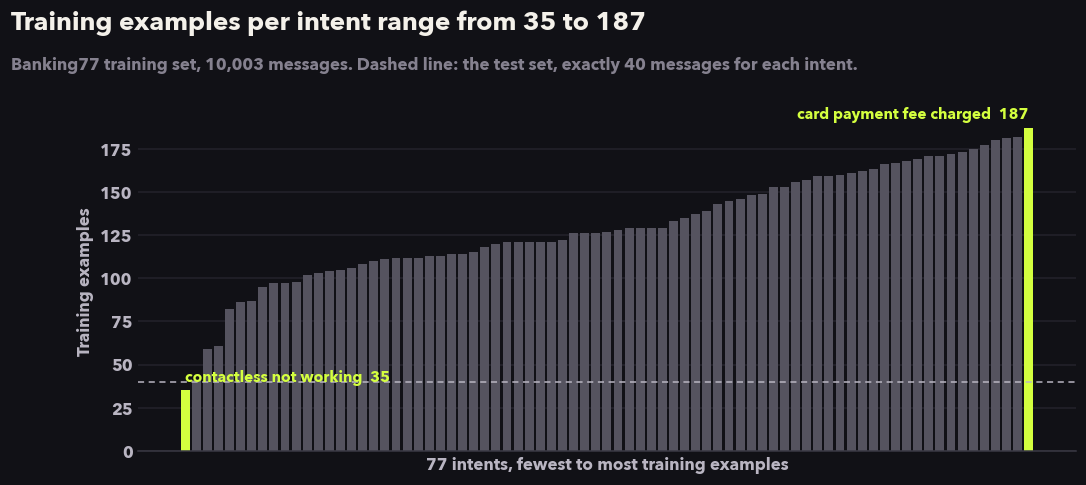

In [2]:
counts = per_intent.sort_values()
fig, ax = plt.subplots(figsize=(11, 4.6))
colours = [style.HIGHLIGHT if c in (counts.min(), counts.max()) else style.APPROACH_COLORS["frozen"]
           for c in counts]
ax.bar(range(len(counts)), counts.values, color=colours, width=0.8)
ax.axhline(40, color=style.INK_2, linewidth=1, linestyle=(0, (4, 3)))
for i in (0, len(counts) - 1):
    ax.annotate(f"{counts.index[i].replace('_', ' ')}  {counts.iloc[i]}", (i, counts.iloc[i]),
                xytext=(0, 6), textcoords="offset points", ha="left" if i == 0 else "right",
                color=style.HIGHLIGHT, fontsize=10)
ax.set_xticks([])
ax.set_xlabel("77 intents, fewest to most training examples")
ax.set_ylabel("Training examples")
ax.grid(axis="y")
ax.grid(axis="x", visible=False)
fig.subplots_adjust(top=0.78)
style.headline(fig, f"Training examples per intent range from {counts.min()} to {counts.max()}",
               "Banking77 training set, 10,003 messages. Dashed line: the test set, exactly 40 messages for each intent.")
style.save(fig, "intent_counts")

## 2. Short messages, long label list

Messages are short. That matters for cost later: when a hosted model is prompted, the list of 77 intent names (and any examples) is far longer than the message itself, so the fixed part of the prompt, not the customer's words, drives the price.

In [3]:
words = test["text"].str.split().str.len()
label_list = "\n".join(labels)
pd.DataFrame({
    "Median": [int(words.median()), int(test["text"].str.len().median())],
    "90th percentile": [int(words.quantile(0.9)), int(test["text"].str.len().quantile(0.9))],
    "The 77 intent names, as one list": [len(label_list.split()), len(label_list)],
}, index=["Words", "Characters"])

,Median,90th percentile,"The 77 intent names, as one list"
Words,9,18,77
Characters,45,90,1648


## 3. How far does a model with no fine-tuning get?

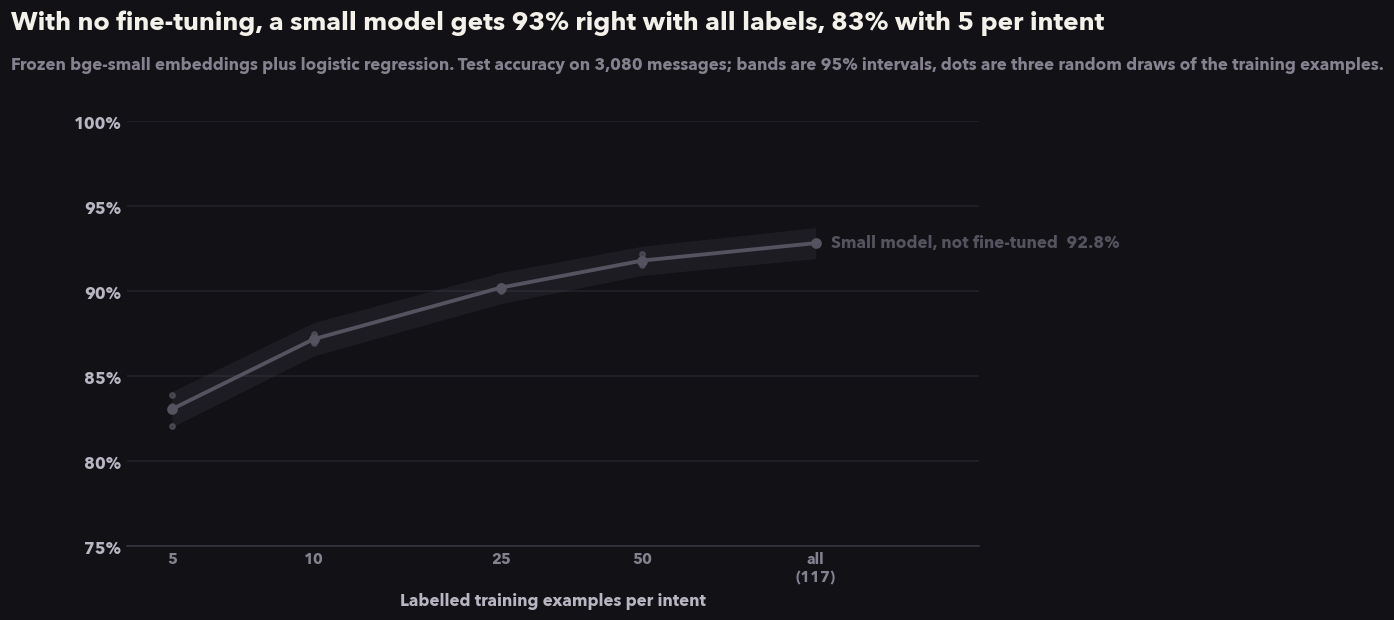

In [4]:
runs = pd.read_csv(RESULTS_DIR / "runs_frozen.csv")
frozen = learning_curve_summary("frozen")
full = frozen.set_index("n_per_class").loc["all"]
five = frozen.set_index("n_per_class").loc[5]

fig, ax = plots.learning_curve([frozen])
ax.set_ylim(0.75, 1.0)
ax.set_xlim(4, 260)
fig.subplots_adjust(top=0.80)
style.headline(
    fig,
    f"With no fine-tuning, a small model gets {full['accuracy']:.0%} right with all labels, {five['accuracy']:.0%} with 5 per intent",
    "Frozen bge-small embeddings plus logistic regression. Test accuracy on 3,080 messages; "
    "bands are 95% intervals, dots are three random draws of the training examples.")
style.save(fig, "frozen_learning_curve")

In [5]:
table = frozen[["n_per_class", "accuracy", "low", "high"]].copy()
table["Seeds (each)"] = frozen["seed_accuracies"].apply(lambda a: ", ".join(f"{x:.1%}" for x in a))
table["Training time (seconds)"] = runs.groupby(runs["n_per_class"].astype(str))["train_seconds"].mean().reindex(
    table["n_per_class"].astype(str)).round(2).to_numpy()
table.columns = ["Examples per intent", "Accuracy", "95% low", "95% high", "Seeds (each)", "Training time (seconds)"]
table.style.format({"Accuracy": "{:.1%}", "95% low": "{:.1%}", "95% high": "{:.1%}"}).hide(axis="index")

Examples per intent,Accuracy,95% low,95% high,Seeds (each),Training time (seconds)
5,83.1%,82.0%,84.1%,"83.9%, 82.1%, 83.2%",0.090000
10,87.2%,86.2%,88.1%,"87.1%, 87.5%, 86.9%",0.130000
25,90.2%,89.3%,91.1%,"90.3%, 90.3%, 90.0%",0.230000
50,91.8%,90.9%,92.6%,"91.7%, 91.6%, 92.2%",0.440000
all,92.8%,91.9%,93.7%,92.8%,1.370000


## 4. Which intents get mixed up?

The model trained on all labels makes about 1 error in 14. The most common confusions are between intents that a person could also mix up.

In [6]:
pred = load_predictions("frozen", "all", 0)
wrong = pred[~pred["correct"]].copy()
wrong["true"] = [labels[i] for i in wrong["label"]]
wrong["predicted"] = [labels[i] for i in wrong["pred"]]
wrong["text"] = test["text"].to_numpy()[wrong["row"]]
pairs = (wrong.groupby(["true", "predicted"]).agg(errors=("text", "size"), example=("text", "first"))
         .sort_values("errors", ascending=False).head(8).reset_index())
pairs["true"] = pairs["true"].str.replace("_", " ")
pairs["predicted"] = pairs["predicted"].str.replace("_", " ")
pairs.columns = ["True intent", "Predicted as", "Errors (of 40)", "Example message"]
pairs.style.hide(axis="index")

True intent,Predicted as,Errors (of 40),Example message
pending transfer,transfer not received by recipient,5,Why hasn't my transfer gone through yet?
top up reverted,top up failed,4,The app wouldn't accept my top up.
fiat currency support,exchange via app,4,How do I change currencies to euros?
balance not updated after bank transfer,transfer timing,4,How long does it take for an international transfer into my account?
top up by bank transfer charge,transfer fee charged,4,"I need to make a transfer, what will the fee be?"
transfer timing,balance not updated after bank transfer,3,What is the fastest that I can make a transfer?
transfer not received by recipient,balance not updated after bank transfer,3,The transfer I did hasn't arrived
wrong amount of cash received,declined cash withdrawal,3,Why did I not get my cash back after I withdrew?


In [7]:
share_top = pairs["Errors (of 40)"].sum() / len(wrong)
print(f"{len(wrong)} errors in total; the 8 most common confusions account for {share_top:.0%} of them, "
      f"so the rest are spread thinly across many pairs of intents.")

221 errors in total; the 8 most common confusions account for 14% of them, so the rest are spread thinly across many pairs of intents.


## What this means

- **The cheapest option sets a high bar.** A frozen embedding model with a linear classifier trains in about a second on a laptop and needs no GPU to serve. Fine-tuning and large hosted models now have to beat it by enough to pay for themselves.
- **Labels matter, but with diminishing returns.** Going from 5 to 25 examples per intent buys much more than going from 50 to all of them. Notebook 03 asks whether fine-tuning bends this curve upwards.
- **The worst confusions are look-alike intents, but errors are spread thinly.** No single fix removes most of them. Some may be labelling ambiguity rather than model mistakes, which caps the accuracy any approach can reach; notebook 02 checks a sample by hand.

**What the data can't tell us.** This is one task with short, single-intent messages in English. A task with longer inputs, rarer classes or open-ended answers could favour a different approach.